In [1]:
%pip uninstall -y clip -q
%pip install git+https://github.com/openai/CLIP.git -q

Note: you may need to restart the kernel to use updated packages.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade \
    torch==2.9.0 torchvision==0.24.0 \
    --index-url https://download.pytorch.org/whl/cu126 -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from PIL import Image
import clip

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Compose, Resize, CenterCrop, ToTensor, Normalize
print("Torch version:", torch.__version__)

from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

Torch version: 2.9.0+cu126


In [4]:
MODELS = {
    "ViT-B/32":"https://openaipublic.azureedge.net/clip/models/40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af/ViT-B-32.pt",
}

In [5]:
! wget {MODELS["ViT-B/32"]} -O model.pt
! pip install ftfy regex
! wget https://openaipublic.azureedge.net/clip/bpe_simple_vocab_16e6.txt.gz -O bpe_simple_vocab_16e6.txt.gz

--2026-11-25 12:28:15--  https://openaipublic.azureedge.net/clip/models/40d365715913c9da98579312b702a82c18be219cc2a73407c4526f58eba950af/ViT-B-32.pt
Resolving openaipublic.azureedge.net (openaipublic.azureedge.net)... 150.171.110.194, 2603:1061:14:1c2::1
Connecting to openaipublic.azureedge.net (openaipublic.azureedge.net)|150.171.110.194|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 353976522 (338M) [application/octet-stream]
Saving to: ‘model.pt’

model.pt            100%[===================>] 337.58M   140MB/s    in 2.4s    

2026-11-25 12:28:17 (140 MB/s) - ‘model.pt’ saved [353976522/353976522]

--2026-11-25 12:28:19--  https://openaipublic.azureedge.net/clip/bpe_simple_vocab_16e6.txt.gz
Resolving openaipublic.azureedge.net (openaipublic.azureedge.net)... 150.171.110.194, 2603:1061:14:1c1::1
Connecting to openaipublic.azureedge.net (openaipublic.azureedge.net)|150.171.110.194|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1356

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

clip_model, preprocess = clip.load(
    "ViT-B/32",
    device=device,
    jit=False
)

In [7]:
DATA_DIR = "/kaggle/input/competitions/planttraits2024"
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
    
target_cols = [
    "X4_mean",
    "X11_mean",
    "X18_mean",
    "X26_mean",
    "X50_mean",
    "X3112_mean"
]

targets = train[target_cols].to_numpy(dtype="float32")
targets

array([[4.0175313e-01, 1.1758108e+01, 1.1748430e-01, 1.2437791e+00,
        1.8493754e+00, 5.0216034e+01],
       [4.8033369e-01, 1.5748846e+01, 3.8931507e-01, 6.4294028e-01,
        1.3534679e+00, 5.7409845e+02],
       [7.9691690e-01, 5.2912512e+00, 8.5529079e+00, 3.9524123e-01,
        2.3431525e+00, 1.1300967e+03],
       ...,
       [6.3965905e-01, 5.5495958e+00, 2.7173948e+00, 1.0206478e+01,
        2.7225990e+00, 6.0222986e+02],
       [7.7464157e-01, 7.0242176e+00, 4.4296594e+00, 9.3721695e+00,
        3.2517385e+00, 2.4438718e+02],
       [5.5188811e-01, 1.3169623e+01, 5.8272266e+00, 1.5477333e+02,
        1.5239780e+00, 3.7400657e+03]], dtype=float32)

In [8]:
class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir,
                 feature_cols, target_cols,
                 transform=None, target_transform=None):

        self.img_labels = annotations_file.reset_index(drop=True)
        self.img_dir = img_dir

        self.feature_cols = feature_cols
        self.target_cols = target_cols

        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        row = self.img_labels.iloc[idx]

        image_id = int(row["id"])
        img_path = os.path.join(
            self.img_dir, f"{image_id}.jpeg"
        )

        image = Image.open(img_path).convert("RGB")

        label = torch.tensor(
            row[self.target_cols].to_numpy(dtype="float32")
        )

        tabular = torch.tensor(
            row[self.feature_cols].to_numpy(dtype="float32")
        )

        if self.transform:
            image = self.transform(image)

        if self.target_transform:
            label = self.target_transform(label)

        return image, tabular, label

In [9]:
feature_cols = [
    col for col in test.columns
    if col != "id"
    and col in train.columns
    and pd.api.types.is_numeric_dtype(train[col])
    and pd.api.types.is_numeric_dtype(test[col])
]

In [10]:
train_dataset = CustomImageDataset(
    annotations_file=train,
    img_dir=f"{DATA_DIR}/train_images",
    feature_cols=feature_cols,
    target_cols=target_cols,
    transform=preprocess
)
test_dataset = CustomImageDataset(
    annotations_file=test,
    img_dir=f"{DATA_DIR}/test_images",
    transform=preprocess,
    target_cols = target_cols,
    feature_cols=feature_cols
)

In [11]:
train_dataloader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=True, num_workers = 2)

images, tabular, labels = next(iter(train_dataloader))

print("Images:", images.shape)
print("Labels", labels.shape)
print("Labels:", labels.shape)

Images: torch.Size([64, 3, 224, 224])
Labels torch.Size([64, 6])
Labels: torch.Size([64, 6])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7338688..2.145897].


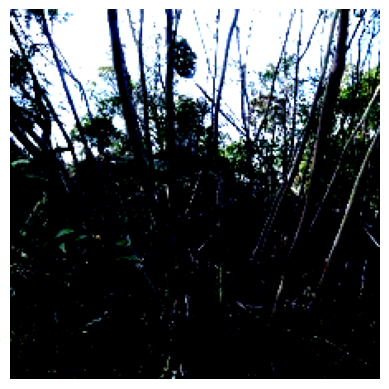

Label: tensor([8.0553e-01, 5.1413e+00, 1.1804e+01, 1.2952e+00, 2.3666e+00, 1.3008e+03])


'\nТаргет\t    Что означает\nX4_mean\t    Плотность древесины или стебля — отношение сухой массы стебля к его объёму\nX11_mean\tУдельная площадь листа (SLA) — площадь листа на единицу его сухой массы\nX18_mean\tВысота растения\nX26_mean\tСухая масса семени\nX50_mean\tСодержание азота на единицу площади листа\nX3112_mean\tПлощадь листа, включая случай сложных листьев\n'

In [12]:
img = images[0].permute(1, 2, 0)
label = labels[0]

plt.imshow(img)
plt.axis("off")

plt.show()

print(f"Label: {label}")

'''
Таргет	    Что означает
X4_mean	    Плотность древесины или стебля — отношение сухой массы стебля к его объёму
X11_mean	Удельная площадь листа (SLA) — площадь листа на единицу его сухой массы
X18_mean	Высота растения
X26_mean	Сухая масса семени
X50_mean	Содержание азота на единицу площади листа
X3112_mean	Площадь листа, включая случай сложных листьев
'''

In [13]:
feature_cols = [
    col for col in test.select_dtypes(include="number").columns
    if col != "id" and col in train.columns
]
feature_cols

['WORLDCLIM_BIO1_annual_mean_temperature',
 'WORLDCLIM_BIO12_annual_precipitation',
 'WORLDCLIM_BIO13.BIO14_delta_precipitation_of_wettest_and_dryest_month',
 'WORLDCLIM_BIO15_precipitation_seasonality',
 'WORLDCLIM_BIO4_temperature_seasonality',
 'WORLDCLIM_BIO7_temperature_annual_range',
 'SOIL_bdod_0.5cm_mean_0.01_deg',
 'SOIL_bdod_100.200cm_mean_0.01_deg',
 'SOIL_bdod_15.30cm_mean_0.01_deg',
 'SOIL_bdod_30.60cm_mean_0.01_deg',
 'SOIL_bdod_5.15cm_mean_0.01_deg',
 'SOIL_bdod_60.100cm_mean_0.01_deg',
 'SOIL_cec_0.5cm_mean_0.01_deg',
 'SOIL_cec_100.200cm_mean_0.01_deg',
 'SOIL_cec_15.30cm_mean_0.01_deg',
 'SOIL_cec_30.60cm_mean_0.01_deg',
 'SOIL_cec_5.15cm_mean_0.01_deg',
 'SOIL_cec_60.100cm_mean_0.01_deg',
 'SOIL_cfvo_0.5cm_mean_0.01_deg',
 'SOIL_cfvo_100.200cm_mean_0.01_deg',
 'SOIL_cfvo_15.30cm_mean_0.01_deg',
 'SOIL_cfvo_30.60cm_mean_0.01_deg',
 'SOIL_cfvo_5.15cm_mean_0.01_deg',
 'SOIL_cfvo_60.100cm_mean_0.01_deg',
 'SOIL_clay_0.5cm_mean_0.01_deg',
 'SOIL_clay_100.200cm_mean_0.01_d

In [14]:
class TabularEncoder(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU()
        )
    def forward(self, x):
        return self.encoder(x)

In [15]:
class MultimodalNetwork(nn.Module):
    def __init__(self, feature_cols):
        super().__init__()
        
        self.image_model = clip_model
        for param in self.image_model.parameters():
            param.requires_grad = False
        self.image_model.eval()
        
        self.tabular_encoder = TabularEncoder(n_features=len(feature_cols))

        self.regression_head = nn.Sequential(
            nn.Linear(640,128),
            nn.ReLU(),
            nn.Linear(128,6)
        )
    def forward(self, image_emb, tabular):
        tabular_emb = self.tabular_encoder(tabular.float())
    
        combined = torch.cat([image_emb.float(), tabular_emb], dim=1)
    
        return self.regression_head(combined)

In [22]:
model = MultimodalNetwork(feature_cols=feature_cols).to(device)
images = images.to(device)
tabular = tabular.float().to(device)
labels = labels.to(device)

In [23]:
feature_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

train_df, val_df = train_test_split(
    train,
    test_size = 0.2,
    random_state=42,
    shuffle=True
)
outlier_cols = [
    col for col in target_cols
    if col != "X4_mean"
]

upper_bounds = train_df[outlier_cols].quantile(0.999)

mask = (
    train_df[outlier_cols] <= upper_bounds
).all(axis=1)

train_df = train_df.loc[mask].copy()

train_df = train_df.copy()
val_df = val_df.copy()

train_df[feature_cols] = feature_pipeline.fit_transform(
    train_df[feature_cols]
)

val_df[feature_cols] = feature_pipeline.transform(
    val_df[feature_cols]
)

target_scaler = StandardScaler()

train_df[target_cols] = target_scaler.fit_transform(
    train_df[target_cols]
)

val_df[target_cols] = target_scaler.transform(
    val_df[target_cols]
)

train_dataset = CustomImageDataset(
    annotations_file=train_df,
    img_dir=f"{DATA_DIR}/train_images",
    feature_cols=feature_cols,
    target_cols=target_cols,
    transform=preprocess
)

val_dataset = CustomImageDataset(
    annotations_file=val_df,
    img_dir=f"{DATA_DIR}/train_images",
    feature_cols=feature_cols,
    target_cols=target_cols,
    transform=preprocess
)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

val_dataloader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

In [24]:
def train_epoch(model, dataloader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for image_emb, tabular, labels in progress_bar:
        images = images.to(device)
        tabular = tabular.float().to(device)
        labels = labels.float().to(device)

        optimizer.zero_grad()

        predictions = model(image_emb, tabular)
        loss = criterion(predictions, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        progress_bar.set_postfix(
            batch_loss=f"{loss.item():.4f}",
            avg_loss=f"{total_loss / max(1, progress_bar.n * dataloader.batch_size):.4f}"
        )

    return total_loss / len(dataloader.dataset)

In [29]:
def inverse_targets(values):
    return target_scaler.inverse_transform(values)

def validate(model, dataloader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, tabular, labels in tqdm(
            dataloader,
            desc="Validation",
            leave=False
        ):

            images = images.to(device, non_blocking=True)
            tabular = tabular.float().to(device, non_blocking=True)
            labels = labels.float().to(device, non_blocking=True)

            predictions = model(images, tabular)
            loss = criterion(predictions, labels)

            batch_size = images.size(0)

            total_loss += loss.item() * batch_size
            total_samples += batch_size

            all_predictions.append(predictions.cpu())
            all_labels.append(labels.cpu())

    all_predictions = torch.cat(
        all_predictions, dim=0
    ).numpy()

    all_labels = torch.cat(
        all_labels, dim=0
    ).numpy()

    val_loss = total_loss / total_samples

    # Возвращаем исходный масштаб таргетов
    y_true = inverse_targets(
        all_labels.astype(np.float64)
    )

    y_pred = inverse_targets(
        all_predictions.astype(np.float64)
    )

    # R2 по всем наблюдениям
    scores = r2_score(
        y_true,
        y_pred,
        multioutput="raw_values"
    )

    filtered_scores = []
    sse_top10 = []

    for i, col in enumerate(target_cols):

        # R2 без экстремальных наблюдений
        if col in upper_bounds.index:
            mask = y_true[:, i] <= upper_bounds[col]
        else:
            mask = np.ones(len(y_true), dtype=bool)

        filtered_score = (
            r2_score(y_true[mask, i], y_pred[mask, i])
            if mask.sum() >= 2 else np.nan
        )

        filtered_scores.append(filtered_score)

        # Вклад крупнейших ошибок в SSE
        errors = (y_true[:, i] - y_pred[:, i]) ** 2
        errors = np.sort(errors)[::-1]

        contribution = (
            errors[:10].sum() / errors.sum()
            if errors.sum() > 0 else 0.0
        )

        sse_top10.append(contribution * 100)

    print(pd.DataFrame({
        "Target": target_cols,
        "Original R2": scores,
        "Filtered R2": filtered_scores,
        "Top 10 SSE (%)": sse_top10
    }).round(6))

    val_r2 = scores.mean()

    return val_loss, val_r2

In [30]:
model = MultimodalNetwork(
    feature_cols=feature_cols
).to(device)

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3
)

criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-3
)

criterion = nn.MSELoss()
num_epochs = 20

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    train_loss = train_epoch(
        model, train_dataloader,
        optimizer, criterion, device
    )

    val_loss, val_r2 = validate(
        model, val_dataloader,
        criterion, device
    )

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}")
    print(f"R²: {val_r2:.4f}")


Epoch 1/20


Training:   0%|          | 0/173 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

       Target  Original R2  Filtered R2  Top 10 SSE (%)
0     X4_mean     0.222280     0.222280       27.403973
1    X11_mean    -0.000088     0.143669       99.999956
2    X18_mean    -0.000181     0.416431      100.000000
3    X26_mean    -0.000210     0.106603       99.999845
4    X50_mean    -0.000098     0.126447       99.999719
5  X3112_mean    -0.000090     0.199006      100.000000
Train Loss: 0.8237
Val Loss: 59051810245.1434
R²: 0.0369

Epoch 2/20


Training:   0%|          | 0/173 [00:00<?, ?it/s]

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

... (41 outputs left out)

Validation:   0%|          | 0/44 [00:00<?, ?it/s]

       Target  Original R2  Filtered R2  Top 10 SSE (%)
0     X4_mean     0.235214     0.235214       27.648125
1    X11_mean    -0.000072     0.178733       99.999958
2    X18_mean    -0.000181     0.459967      100.000000
3    X26_mean    -0.000217     0.094624       99.999848
4    X50_mean    -0.000093     0.155842       99.999720
5  X3112_mean    -0.000090     0.200284      100.000000
Train Loss: 0.5943
Val Loss: 59051810240.2968
R²: 0.0391

Epoch 17/20


Training:   0%|          | 0/173 [00:00<?, ?it/s]

KeyboardInterrupt: 